# Big West Predictor | 2021–2026


In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('../data/processed')

In [2]:
results = pd.read_csv(DATA_DIR / 'bigwest_2019_2026_results.csv', dtype={'athlete_id': 'Int64'})
team_scores = pd.read_csv(DATA_DIR / 'bigwest_2021_2026_team_scores.csv')
roster = pd.read_csv(DATA_DIR / 'bigwest_roster.csv', dtype={'athlete_id': 'Int64'})
regular_season = pd.read_csv(DATA_DIR / 'regular_season.csv', dtype={'athlete_id': 'Int64'})
national_rank = pd.read_csv(DATA_DIR / 'national_event_ranking.csv')

results_2021 = results[results['meet_year'] == 2021]
results_2021.head()

,athlete_id,athlete_name,team,meet_name,meet_year,gender,event,mark,mark_unit,place,wind,event_type,points,temp
3937,7657050,Benjamin Goodwin,UC Davis,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.67,seconds,1.0,NaN,track,10.0,70.1
3938,6110870,Chineme Allison,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.68,seconds,2.0,NaN,track,8.0,70.1
3939,6597023,Rasaun House,Cal St. Fullerton,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.71,seconds,3.0,NaN,track,6.0,70.1
3940,7152233,Tyler Esteves,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.71,seconds,4.0,NaN,track,5.0,70.1
3941,6163778,Kent Harris,Long Beach St.,2021 Big West Outdoor Track & Field Championships,2021,men,Men's 100 Meters,10.77,seconds,5.0,NaN,track,4.0,70.1


## 2021: Predicting championship marks from regular-season marks

For each athlete's championship event, we build five features from their 2021 regular-season marks in that same event (outdoor meets before the championships on May 12, 2021 only; indoor marks aren't comparable, and 2021 had no indoor season anyway). Then we fit a one-feature linear regression for each feature and score it with R².

If an athlete has several marks at one meet (e.g. prelim + final), we keep their best mark from that meet.

| Feature | Definition |
|---|---|
| Season median | Median mark across the season's meets |
| Mean of last 3 meets | Average of the last 3 meets before the championships |
| Most recent meet | The last meet before the championships |
| Wind-legal season best | Best mark with wind ≤ +2.0 m/s. Only differs from season best in the 100, 200, hurdles, long jump and triple jump. Marks with no wind reading don't count as legal. |
| Season best | Best mark of the season |

**Target:** the athlete's championship mark from `results` (their final if they made it, otherwise their prelim). Relays and multi-events are excluded, as are DNF, FOUL, NH, etc. A championship mark more than 50% worse than the athlete's own season best is treated like a DNF too (e.g. injured and jogged in). In 2021 that's one race: a 1:40.56 in the men's 400m final from a runner who ran 48.28 in the prelims.

**Two R² scores** (both use the same athletes; they differ in *which differences* they try to explain):
- **Raw R²** fits one line across every event. It comes out near 1.0 for every feature because events are on different scales (a 10k takes ~30 minutes, a 100m ~11 seconds), so it doesn't tell the features apart.
- **Within-event R²** first converts each mark to "standard deviations from the event average" (same gender + event). It measures how well a feature predicts who does better *within* an event. **Use this one to compare features.**

In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# First day of each Big West Championships; only regular-season marks before it count
CHAMPS_START = {2021: '2021-05-12', 2022: '2022-05-13', 2023: '2023-05-12', 2024: '2024-05-10',
                2025: '2025-05-16', 2026: '2026-05-15'}  # 2026: main meet (multi-events were May 8-9)
WIND_EVENTS = {'100', '200', '100H', '110H', 'LJ', 'TJ'}
WIND_LIMIT = 2.0  # m/s
MIN_ATHLETES_PER_EVENT = 5  # need a few athletes to standardize within an event
MAX_OFF_SEASON_BEST = 0.5  # championship marks >50% worse than the athlete's season best aren't a real race

# Championship event names -> regular-season event codes
EVENT_CODES = {
    '100 Meters': '100', '200 Meters': '200', '400 Meters': '400', '800 Meters': '800',
    '1500 Meters': '1500', '5000 Meters': '5000', '10,000 Meters': '10,000',
    '100 Hurdles': '100H', '110 Hurdles': '110H', '400 Hurdles': '400H',
    '3000 Steeplechase': '3000S',
    'High Jump': 'HJ', 'Pole Vault': 'PV', 'Long Jump': 'LJ', 'Triple Jump': 'TJ',
    'Shot Put': 'SP', 'Discus': 'DT', 'Hammer': 'HT', 'Javelin': 'JT',
}

FEATURES = {
    'median_mark': 'Season median',
    'last3_mean': 'Mean of last 3 meets',
    'most_recent': 'Most recent meet',
    'wind_legal_sb': 'Wind-legal season best',
    'season_best': 'Season best',
}

# Events held only indoors / only outdoors, used to tell indoor meets apart
INDOOR_ONLY_EVENTS = {'60', '60H', 'WT', 'Pent'}
OUTDOOR_ONLY_EVENTS = {'100', '100H', '110H', '400H', '3000S', '10,000', 'DT', 'HT', 'JT', '4x100', 'Dec'}


def to_number(mark):
    """'10.74' -> 10.74, '3:44.68' -> 224.68, '7.45m' -> 7.45, 'DNF'/'FOUL' -> NaN."""
    text = str(mark).strip().removesuffix('m')
    try:
        return sum(float(part) * 60**i for i, part in enumerate(reversed(text.split(':'))))
    except ValueError:
        return np.nan


# A meet is indoor if "Indoor" is in its name, or it has no outdoor-only events
# and either has indoor-only events or is in January/February.
meet_events = regular_season.groupby(['meet_name', 'meet_start_date'])['event']
has_outdoor_event = meet_events.transform(lambda e: e.isin(OUTDOOR_ONLY_EVENTS).any())
has_indoor_event = meet_events.transform(lambda e: e.isin(INDOOR_ONLY_EVENTS).any())
jan_or_feb = pd.to_datetime(regular_season['meet_start_date']).dt.month <= 2
regular_season['is_indoor'] = (regular_season['meet_name'].str.contains('indoor', case=False)
                               | (~has_outdoor_event & (has_indoor_event | jan_or_feb)))


def season_features(g):
    best = 'min' if g['lower_is_better'].iat[0] else 'max'
    # One mark per meet (the athlete's best there), in date order
    per_meet = g.groupby(['date', 'meet_name'])['mark_num'].agg(best).sort_index()
    legal = g.loc[g['wind_legal'], 'mark_num']
    return pd.Series({
        'n_meets': len(per_meet),
        'median_mark': per_meet.median(),
        'last3_mean': per_meet.tail(3).mean(),
        'most_recent': per_meet.iloc[-1],
        'wind_legal_sb': legal.agg(best) if len(legal) else np.nan,
        'season_best': per_meet.agg(best),
    })


def build_model_data(year):
    """One row per athlete-event at that year's championships, with regular-season features."""
    # Target: championship mark (individual track and field events)
    champs = results[(results['meet_year'] == year)
                     & results['event_type'].isin(['track', 'field'])].copy()
    champs['gender'] = champs['gender'].str.capitalize()
    champs['event_code'] = (champs['event']
                            .str.replace(r"^(?:Men|Women)'s ", '', regex=True)
                            .map(EVENT_CODES))
    assert champs['event_code'].notna().all(), 'Unmapped championship event'
    champs['final_mark'] = champs['mark'].map(to_number)
    champs = champs.dropna(subset=['athlete_id', 'final_mark'])  # drops DNF, FOUL, NH, ...

    # Outdoor regular-season marks from before the championships
    season = regular_season[(regular_season['year'] == year) & ~regular_season['is_indoor']].copy()
    season['date'] = pd.to_datetime(season['meet_start_date'])
    season = season[season['date'] < pd.Timestamp(CHAMPS_START[year])]
    season = season.rename(columns={'event': 'event_code'})
    season['mark_num'] = season['mark'].map(to_number)
    season = season.dropna(subset=['mark_num'])
    season['lower_is_better'] = season['event_type'].eq('track')
    season['wind_legal'] = ~season['event_code'].isin(WIND_EVENTS) | (season['wind'] <= WIND_LIMIT)

    keys = ['athlete_id', 'gender', 'event_code']
    features = season.groupby(keys).apply(season_features, include_groups=False).reset_index()

    # Keep athletes with every feature, so all five models use the same rows
    data = champs.merge(features, on=keys, how='inner').dropna(subset=list(FEATURES))

    # Treat marks far off the athlete's own season best like a DNF (e.g. injured and jogged in)
    off_best = np.where(data['event_type'] == 'track',
                        data['final_mark'] / data['season_best'] - 1,
                        1 - data['final_mark'] / data['season_best'])
    not_a_race = off_best > MAX_OFF_SEASON_BEST
    if not_a_race.any():
        print(f'{year}: dropped as not a real race:')
        print(data.loc[not_a_race, ['event', 'athlete_name', 'final_mark', 'season_best']].to_string(index=False))
    data = data[~not_a_race]

    event_size = data.groupby('event')['athlete_id'].transform('size')
    data = data[event_size >= MIN_ATHLETES_PER_EVENT].copy()
    print(f'{year}: {len(champs)} championship marks -> {len(data)} with regular-season '
          f'marks in the same event {data["event_type"].value_counts().to_dict()}')
    return data


model_data = build_model_data(2021)
model_data[['athlete_name', 'gender', 'event_code', 'final_mark', 'n_meets', *FEATURES]].head()

2021: dropped as not a real race:
           event    athlete_name  final_mark  season_best
Men's 400 Meters Marcel Espinoza      100.56        47.47
2021: 581 championship marks -> 532 with regular-season marks in the same event {'track': 275, 'field': 257}


,athlete_name,gender,event_code,final_mark,n_meets,median_mark,last3_mean,most_recent,wind_legal_sb,season_best
0,Benjamin Goodwin,Men,100,10.67,4.0,10.855,10.806667,10.67,10.67,10.67
1,Chineme Allison,Men,100,10.68,6.0,10.705,10.650000,10.52,10.65,10.52
2,Rasaun House,Men,100,10.71,4.0,10.800,10.816667,10.84,10.76,10.75
3,Tyler Esteves,Men,100,10.71,2.0,10.660,10.660000,10.55,10.55,10.55
4,Kent Harris,Men,100,10.77,2.0,10.820,10.820000,10.77,10.77,10.77


In [4]:
def zscore_within_event(df, col):
    """Standard deviations from the average for the same gender + event."""
    grp = df.groupby(['gender', 'event_code'])[col]
    return (df[col] - grp.transform('mean')) / grp.transform('std')


def fit_r2(x, y):
    X = np.asarray(x).reshape(-1, 1)
    model = LinearRegression().fit(X, y)
    return r2_score(y, model.predict(X))


for col in [*FEATURES, 'final_mark']:
    model_data[f'{col}_z'] = zscore_within_event(model_data, col)

subsets = {
    'All': model_data,
    'Track': model_data[model_data['event_type'] == 'track'],
    'Field': model_data[model_data['event_type'] == 'field'],
}

rows = []
for feature, label in FEATURES.items():
    for subset, df in subsets.items():
        rows.append({
            'feature': label,
            'subset': subset,
            'within_event_r2': fit_r2(df[f'{feature}_z'], df['final_mark_z']),
            'raw_r2': fit_r2(df[feature], df['final_mark']),
        })
r2_results = pd.DataFrame(rows)

within_r2 = r2_results.pivot(index='feature', columns='subset', values='within_event_r2')[list(subsets)]
raw_r2 = r2_results.pivot(index='feature', columns='subset', values='raw_r2')[list(subsets)]

print('Rows per subset:', {name: len(df) for name, df in subsets.items()})
print('Best feature per subset:', within_r2.idxmax().to_dict())
print('\nWithin-event R² (use this to compare features)')
display(within_r2.sort_values('All', ascending=False).round(3))
print('Raw R² (one line across all events; near 1.0 because of event scale differences)')
display(raw_r2.round(4))

Rows per subset: {'All': 532, 'Track': 275, 'Field': 257}
Best feature per subset: {'All': 'Season best', 'Track': 'Wind-legal season best', 'Field': 'Mean of last 3 meets'}

Within-event R² (use this to compare features)


subset,All,Track,Field
feature,,,
Season best,0.622,0.635,0.607
Season median,0.619,0.624,0.612
Wind-legal season best,0.617,0.637,0.597
Mean of last 3 meets,0.607,0.597,0.617
Most recent meet,0.568,0.575,0.560


Raw R² (one line across all events; near 1.0 because of event scale differences)


subset,All,Track,Field
feature,,,
Mean of last 3 meets,0.9993,0.9991,0.9910
Most recent meet,0.9993,0.9991,0.9884
Season best,0.9993,0.9992,0.9922
Season median,0.9993,0.9991,0.9913
Wind-legal season best,0.9993,0.9992,0.9922


### R² for each event on its own

Same idea as within-event R², but with a separate line fit for each event (e.g. men's 100m season best → men's 100m championship mark). The combined numbers above are roughly a weighted blend of these.

Check `n` before reading too much into a row. With ~15 athletes, one unusual race can move an event's R² a lot.

In [5]:
labels = list(FEATURES.values())

rows = []
for (event_type, event), df in model_data.groupby(['event_type', 'event']):
    row = {'event_type': event_type, 'event': event, 'n': len(df)}
    for feature, label in FEATURES.items():
        row[label] = fit_r2(df[feature], df['final_mark'])
    rows.append(row)

per_event_r2 = (pd.DataFrame(rows)
                .sort_values(['event_type', 'event'], ascending=[False, True])
                .set_index(['event_type', 'event']))

# Best feature per event. Ties are listed together: outside the wind events,
# wind-legal season best and season best are the same number.
scores = per_event_r2[labels]
is_best = scores.ge(scores.max(axis=1) - 1e-9, axis=0)
per_event_r2['Best feature'] = is_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_summary = pd.DataFrame({
    'Median R² (all events)': scores.median(),
    'Median R² (track)': scores.loc['track'].median(),
    'Median R² (field)': scores.loc['field'].median(),
    'Events where best (ties count for each)': is_best.sum(),
})

display(per_event_r2.round(2))
display(per_event_summary.round(3))

n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           14           0.75                  0.82   
           Men's 110 Hurdles          13           0.71                  0.58   
           Men's 1500 Meters          15           0.36                  0.34   
           Men's 200 Meters           15           0.64                  0.61   
           Men's 3000 Steeplechase    12           0.70                  0.63   
           Men's 400 Hurdles          12           0.81                  0.77   
           Men's 400 Meters           14           0.75                  0.52   
           Men's 5000 Meters          22           0.24                  0.24   
           Men's 800 Meters           12           0.66                  0.72   
           Women's 10,000 Meters       5           0.62                  0.62   
           Women's 100 Hurdles        15           0.71                  0.57   
           Women's 100 Meters         16           0.82                  0.81   
           Women's 1500 Meters        21           0.52                  0.55   
           Women's 200 Meters         13           0.50                  0.41   
           Women's 3000 Steeplechase  11           0.85                  0.82   
           Women's 400 Hurdles        11           0.72                  0.54   
           Women's 400 Meters         14           0.62                  0.69   
           Women's 5000 Meters        24           0.68                  0.72   
           Women's 800 Meters         16           0.80                  0.87   
field      Men's Discus               18           0.76                  0.77   
           Men's Hammer               17           0.80                  0.76   
           Men's High Jump            11           0.92                  0.88   
           Men's Javelin              13           0.39                  0.39   
           Men's Long Jump            22           0.35                  0.34   
           Men's Pole Vault           12           0.57                  0.67   
           Men's Shot Put             17           0.67                  0.60   
           Men's Triple Jump          14           0.73                  0.75   
           Women's Discus             23           0.60                  0.65   
           Women's Hammer             20           0.62                  0.63   
           Women's High Jump          13           0.74                  0.75   
           Women's Javelin            12           0.18                  0.17   
           Women's Long Jump          15           0.67                  0.72   
           Women's Pole Vault         19           0.68                  0.71   
           Women's Shot Put           20           0.65                  0.60   
           Women's Triple Jump        11           0.76                  0.82   

                                      Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.63   
           Men's 110 Hurdles                      0.70   
           Men's 1500 Meters                      0.24   
           Men's 200 Meters                       0.56   
           Men's 3000 Steeplechase                0.54   
           Men's 400 Hurdles                      0.53   
           Men's 400 Meters                       0.31   
           Men's 5000 Meters                      0.40   
           Men's 800 Meters                       0.75   
           Women's 10,000 Meters                  0.62   
           Women's 100 Hurdles                    0.80   
           Women's 100 Meters                     0.78   
           Women's 1500 Meters                    0.45   
           Women's 200 Meters                     0.43   
           Women's 3000 Steeplechase              0.81   
           Women's 400 Hurdles                    0.49 

,Median R² (all events),Median R² (track),Median R² (field),Events where best (ties count for each)
Season median,0.675,0.705,0.671,8
Mean of last 3 meets,0.650,0.621,0.692,9
Most recent meet,0.621,0.621,0.630,7
Wind-legal season best,0.631,0.671,0.623,11
Season best,0.631,0.671,0.628,13


## Fit on 2021–2025, test on 2026

Does what we learn from past seasons hold up in a new one? For each event and feature, we fit one line on all five training years together (2021–2025). Then we use that same line, unchanged, to predict the 2026 championship marks from the 2026 regular-season features. 2026 is scored once and never used for fitting.

- **2021–25 (fit):** how well each line fits the athletes it was fit on.
- **2026 (test):** how well it predicts athletes it has never seen. This is the fair measure of a predictor.

On the same 2026 athletes, the table also scores two more predictors:
- **Season best as-is:** no fitting; predict that each athlete matches their season best.
- **Combined model (M4):** the model in `modeling/model_bigwest.py`, also trained on 2021–2025. It predicts on a % vs season best scale using event group, gender, SB level and consistency gap. This cell reads its saved predictions, `modeling/predictions_2026.csv`.

These use one line per event, like the per-event table. Errors are measured in each event's own spread (standard deviations within that year and event), so a 30-second miss in the 5000m doesn't outweigh a 0.2-second miss in the 100m.

Test R² can be **negative**. That means the line did worse than just guessing that every 2026 athlete would hit their event's average.

In [6]:
from tqdm.auto import tqdm

TRAIN_YEARS, TEST_YEAR = [2021, 2022, 2023, 2024, 2025], 2026
FIT_LABEL, TEST_LABEL = f'{TRAIN_YEARS[0]}–{str(TRAIN_YEARS[-1])[2:]} (fit)', f'{TEST_YEAR} (test)'
by_year = {year: build_model_data(year).assign(year=year)
           for year in tqdm(TRAIN_YEARS + [TEST_YEAR], desc='Building features')}
train = pd.concat([by_year[y] for y in TRAIN_YEARS], ignore_index=True)
test = by_year[TEST_YEAR]

skipped = sorted(set(test['event']) - set(train['event']))
if skipped:
    print(f'No training line for these {TEST_YEAR} events (skipped):', skipped)

# One line per event and feature, fit on the training years pooled, then applied to both
parts = []
for event, train_ev in tqdm(train.groupby('event'), desc='Fitting lines'):
    test_ev = test[test['event'] == event]
    for feature, label in FEATURES.items():
        line = LinearRegression().fit(train_ev[[feature]], train_ev['final_mark'])
        for split, df in [(FIT_LABEL, train_ev), (TEST_LABEL, test_ev)]:
            if len(df):
                parts.append(pd.DataFrame({
                    'split': split, 'year': df['year'], 'event': event, 'event_type': df['event_type'],
                    'feature': label, 'athlete_id': df['athlete_id'], 'athlete_name': df['athlete_name'],
                    'actual': df['final_mark'], 'predicted': line.predict(df[[feature]]),
                }))
preds = pd.concat(parts, ignore_index=True)

# Same test athletes, two more predictors: season best as-is, and the combined model
model_preds = pd.read_csv('../modeling/predictions_2026.csv')
model_preds['athlete_id'] = model_preds['athlete_id'].astype('Int64')
test_rows = test.merge(model_preds[['athlete_id', 'event', 'predicted_value', 'sb_value']],
                       on=['athlete_id', 'event'], how='left', validate='one_to_one')
assert test_rows['predicted_value'].notna().all(), f'A {TEST_YEAR} row is missing from the combined model'
assert np.allclose(test_rows['season_best'], test_rows['sb_value']), 'Season bests disagree between the two pipelines'
extra = [pd.DataFrame({'split': TEST_LABEL, 'year': TEST_YEAR, 'event': test_rows['event'],
                       'event_type': test_rows['event_type'], 'feature': label,
                       'athlete_id': test_rows['athlete_id'], 'athlete_name': test_rows['athlete_name'],
                       'actual': test_rows['final_mark'], 'predicted': test_rows[col]})
         for label, col in [('Season best as-is', 'season_best'), ('Combined model (M4)', 'predicted_value')]]
preds = pd.concat([preds, *extra], ignore_index=True)

# Measure errors in each event's own spread (standard deviations within that year and event),
# so events with big numbers (5000m, discus) don't outweigh events with small ones (100m, high jump)
preds['error'] = preds['predicted'] - preds['actual']
by_year_event = preds.groupby(['year', 'event', 'feature'])['actual']
event_sd = by_year_event.transform('std')
preds['error_sd'] = preds['error'] / event_sd
preds['spread_sd'] = (preds['actual'] - by_year_event.transform('mean')) / event_sd


def within_event_r2(df):
    """1 - (prediction errors)² / (differences from the event average)², in event SDs."""
    return 1 - (df['error_sd'] ** 2).sum() / (df['spread_sd'] ** 2).sum()


ORDER = labels + ['Season best as-is', 'Combined model (M4)']
subsets = {'All': preds,
           'Track': preds[preds['event_type'] == 'track'],
           'Field': preds[preds['event_type'] == 'field']}
fit_vs_test = pd.DataFrame({
    (subset, split): df[df['split'] == split].groupby('feature').apply(within_event_r2, include_groups=False)
    for subset, df in subsets.items()
    for split in (FIT_LABEL, TEST_LABEL)
}).reindex(ORDER)

n_test = test['event_type'].value_counts()
print(f'{len(train)} training rows, {len(test)} test rows '
      f'({n_test.get("track", 0)} track, {n_test.get("field", 0)} field), {test["event"].nunique()} events')
print(f'Within-event R²: one line per event fit on {FIT_LABEL[:7]}, scored on both (same {TEST_YEAR} athletes in every row)')
display(fit_vs_test.round(3))

Building features:   0%|          | 0/6 [00:00<?, ?it/s]

2021: dropped as not a real race:
           event    athlete_name  final_mark  season_best
Men's 400 Meters Marcel Espinoza      100.56        47.47
2021: 581 championship marks -> 532 with regular-season marks in the same event {'track': 275, 'field': 257}


2022: 615 championship marks -> 591 with regular-season marks in the same event {'track': 350, 'field': 241}


2023: dropped as not a real race:
           event  athlete_name  final_mark  season_best
Men's 100 Meters Tyler Esteves       31.61        10.49
2023: 663 championship marks -> 630 with regular-season marks in the same event {'track': 357, 'field': 273}


2024: dropped as not a real race:
           event      athlete_name  final_mark  season_best
Men's 100 Meters  Alonzo Floriolli       20.40        10.18
Men's 200 Meters  Alonzo Floriolli       37.61        20.94
 Women's Javelin Rachel Fruchtmann       12.81        36.45
2024: 661 championship marks -> 620 with regular-season marks in the same event {'track': 379, 'field': 241}


2025: 790 championship marks -> 761 with regular-season marks in the same event {'track': 460, 'field': 301}


2026: 754 championship marks -> 701 with regular-season marks in the same event {'track': 419, 'field': 282}


Fitting lines:   0%|          | 0/36 [00:00<?, ?it/s]

3134 training rows, 701 test rows (419 track, 282 field), 35 events
Within-event R²: one line per event fit on 2021–25, scored on both (same 2026 athletes in every row)


All                     Track              \
                       2021–25 (fit) 2026 (test) 2021–25 (fit) 2026 (test)   
feature                                                                      
Season median                  0.544       0.555         0.494       0.533   
Mean of last 3 meets           0.525       0.542         0.477       0.525   
Most recent meet               0.437       0.386         0.375       0.395   
Wind-legal season best         0.550       0.586         0.522       0.579   
Season best                    0.550       0.589         0.519       0.576   
Season best as-is                NaN       0.352           NaN       0.262   
Combined model (M4)              NaN       0.602           NaN       0.576   

                               Field              
                       2021–25 (fit) 2026 (test)  
feature                                           
Season median                  0.614       0.589  
Mean of last 3 meets           0.592       0.568  
Most recent meet               0.524       0.373  
Wind-legal season best         0.590       0.596  
Season best                    0.594       0.608  
Season best as-is                NaN       0.487  
Combined model (M4)              NaN       0.641

### 2026 test results for each event

- **R² table:** how well each line ranks the 2026 athletes in that event, next to season best as-is and the combined model.
- **Average miss table:** how far off the predictions were, on average, in real units (seconds for track, meters for field).

Check `n` before reading too much into a row.

In [7]:
event_order = dict(level=['event_type', 'event'], ascending=[False, True])
test_preds = preds[preds['split'] == TEST_LABEL]
by_event = test_preds.groupby(['event_type', 'event', 'feature'])

per_event_test_r2 = (by_event.apply(within_event_r2, include_groups=False)
                     .unstack('feature')[ORDER].sort_index(**event_order))
per_event_test_r2.insert(0, 'n', test.groupby(['event_type', 'event']).size())
single = per_event_test_r2[labels]
single_best = single.ge(single.max(axis=1) - 1e-9, axis=0)
per_event_test_r2['Best single feature'] = single_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_test_mae = (by_event['error'].apply(lambda e: e.abs().mean())
                      .unstack('feature')[ORDER].sort_index(**event_order))
per_event_test_mae.insert(0, 'unit', ['seconds' if t == 'track' else 'meters'
                                      for t in per_event_test_mae.index.get_level_values('event_type')])

test_summary = pd.DataFrame({
    'Median R² (all events)': per_event_test_r2[ORDER].median(),
    'Median R² (track)': per_event_test_r2.loc['track', ORDER].median(),
    'Median R² (field)': per_event_test_r2.loc['field', ORDER].median(),
    'Events where best single feature (ties count for each)': single_best.sum().reindex(ORDER),
})

print(f'{TEST_YEAR} R² per event')
display(per_event_test_r2.round(2))
print(f'{TEST_YEAR} average miss per event')
display(per_event_test_mae.round(2))
print(f'{TEST_YEAR} summary across events')
display(test_summary.round(3))

2026 R² per event


feature                                n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           28           0.46                  0.49   
           Men's 110 Hurdles          10           0.38                 -0.05   
           Men's 1500 Meters          18           0.44                  0.42   
           Men's 200 Meters           21           0.24                  0.23   
           Men's 3000 Steeplechase    17           0.71                  0.72   
           Men's 400 Hurdles          14           0.85                  0.84   
           Men's 400 Meters           23           0.75                  0.73   
           Men's 5000 Meters          27           0.42                  0.40   
           Men's 800 Meters           20          -0.21                 -0.22   
           Women's 10,000 Meters      11          -0.83                 -0.83   
           Women's 100 Hurdles        18           0.34                  0.40   
           Women's 100 Meters         35           0.85                  0.84   
           Women's 1500 Meters        22           0.72                  0.72   
           Women's 200 Meters         34           0.41                  0.43   
           Women's 3000 Steeplechase  17           0.77                  0.74   
           Women's 400 Hurdles        21           0.79                  0.81   
           Women's 400 Meters         29           0.79                  0.81   
           Women's 5000 Meters        28           0.69                  0.69   
           Women's 800 Meters         26           0.60                  0.59   
field      Men's Discus               17           0.82                  0.74   
           Men's Hammer               20           0.74                  0.67   
           Men's High Jump            13           0.32                  0.46   
           Men's Javelin              14           0.34                  0.11   
           Men's Long Jump            23           0.21                  0.18   
           Men's Pole Vault            9           0.79                  0.84   
           Men's Shot Put             20           0.71                  0.80   
           Men's Triple Jump          14           0.60                  0.52   
           Women's Discus             23           0.69                  0.66   
           Women's Hammer             24           0.64                  0.70   
           Women's High Jump          18           0.29                  0.39   
           Women's Javelin            16           0.85                  0.78   
           Women's Long Jump          22           0.62                  0.51   
           Women's Pole Vault         12           0.61                  0.51   
           Women's Shot Put           23           0.60                  0.66   
           Women's Triple Jump        14           0.66                  0.54   

feature                               Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.18   
           Men's 110 Hurdles                     -0.24   
           Men's 1500 Meters                      0.61   
           Men's 200 Meters                       0.20   
           Men's 3000 Steeplechase                0.73   
           Men's 400 Hurdles                      0.51   
           Men's 400 Meters                       0.65   
           Men's 5000 Meters                      0.36   
           Men's 800 Meters                       0.02   
           Women's 10,000 Meters                 -0.79   
           Women's 100 Hurdles                    0.18   
           Women's 100 Meters                     0.76   
           Women's 1500 Meters                    0.68   
           Women's 200 Meters                    -0.05   
           Women's 3000 Steeplechase              0.70   
           Women

2026 average miss per event


feature                                  unit  Season median  \
event_type event                                               
track      Men's 100 Meters           seconds           0.18   
           Men's 110 Hurdles          seconds           0.23   
           Men's 1500 Meters          seconds           3.34   
           Men's 200 Meters           seconds           0.23   
           Men's 3000 Steeplechase    seconds          10.38   
           Men's 400 Hurdles          seconds           0.50   
           Men's 400 Meters           seconds           0.40   
           Men's 5000 Meters          seconds          18.95   
           Men's 800 Meters           seconds           2.37   
           Women's 10,000 Meters      seconds          48.87   
           Women's 100 Hurdles        seconds           0.29   
           Women's 100 Meters         seconds           0.08   
           Women's 1500 Meters        seconds           3.56   
           Women's 200 Meters         seconds           0.37   
           Women's 3000 Steeplechase  seconds           7.48   
           Women's 400 Hurdles        seconds           0.85   
           Women's 400 Meters         seconds           0.48   
           Women's 5000 Meters        seconds          15.46   
           Women's 800 Meters         seconds           1.99   
field      Men's Discus                meters           1.86   
           Men's Hammer                meters           1.77   
           Men's High Jump             meters           0.04   
           Men's Javelin               meters           3.39   
           Men's Long Jump             meters           0.26   
           Men's Pole Vault            meters           0.07   
           Men's Shot Put              meters           0.43   
           Men's Triple Jump           meters           0.29   
           Women's Discus              meters           2.33   
           Women's Hammer              meters           1.82   
           Women's High Jump           meters           0.04   
           Women's Javelin             meters           1.33   
           Women's Long Jump           meters           0.14   
           Women's Pole Vault          meters           0.10   
           Women's Shot Put            meters           0.43   
           Women's Triple Jump         meters           0.28   

feature                               Mean of last 3 meets  Most recent meet  \
event_type event                                                               
track      Men's 100 Meters                           0.17              0.23   
           Men's 110 Hurdles                          0.30              0.33   
           Men's 1500 Meters                          3.37              2.62   
           Men's 200 Meters                           0.24              0.24   
           Men's 3000 Steeplechase                   10.13              9.88   
           Men's 400 Hurdles                          0.53              0.96   
           Men's 400 Meters                           0.40              0.55   
           Men's 5000 Meters                         19.39             19.52   
           Men's 800 Meters                           2.45              2.12   
           Women's 10,000 Meters                     48.87             49.41   
           Women's 100 Hurdles                        0.29              0.40   
           Women's 100 Meters                         0.08              0.10   
           Women's 1500 Meters                        3.89              4.00   
           Women's 200 Meters                         0.35              0.46   
           Women's 3000 Steeplechase                  8.14              8.06   
           Women's 400 Hurdles                        0.76              1.03   
           Women's 400 Meters                         0.46              0.60   
           Women's 5000 Meters                       15.31             16.69   
           Women's 800 Meters  

2026 summary across events


,Median R² (all events),Median R² (track),Median R² (field),Events where best single feature (ties count for each)
feature,,,,
Season median,0.618,0.598,0.627,5.0
Mean of last 3 meets,0.592,0.592,0.598,6.0
Most recent meet,0.507,0.507,0.448,5.0
Wind-legal season best,0.665,0.711,0.660,14.0
Season best,0.665,0.711,0.660,17.0
Season best as-is,0.500,0.500,0.496,NaN
Combined model (M4),0.686,0.686,0.679,NaN


## Simplest predictor: championship mark = season best

No fitting at all: we predict that each athlete will exactly match their season best at the championships. Nothing is learned, so every year counts as unseen data. We use the same athletes and events as the fitted lines above, so the scores compare directly.

To put every event on one axis, the chart shows each championship mark as a % difference from the athlete's season best. **Positive = worse** than their season best (a slower time, or a shorter jump or throw). Negative = better.

The summary table also splits the error into two parts:
- **Consistent offset:** each event's average miss (e.g. "everyone runs ~1% slower than their season best"). A single number per event could correct this.
- **Athlete-to-athlete scatter:** everything else, i.e. who has a good or bad day. No correction removes this.

In [8]:
# Same athletes and events as the fitted lines above
cols = ['year', 'event_type', 'event', 'athlete_name', 'final_mark', 'season_best']
direct = pd.concat([train, test], ignore_index=True)[cols]
direct = direct[direct['event'].isin(train['event'])].copy()
direct['split'] = np.where(direct['year'] == TEST_YEAR, TEST_LABEL, FIT_LABEL)

# % off season best: positive = worse (slower time, shorter jump or throw)
ratio = direct['final_mark'] / direct['season_best']
direct['pct_off_sb'] = np.where(direct['event_type'] == 'track', ratio - 1, 1 - ratio) * 100

# Score it like the fitted lines: errors measured in each event's own spread
by_year_event = direct.groupby(['year', 'event'])['final_mark']
event_sd = by_year_event.transform('std')
direct['error'] = direct['season_best'] - direct['final_mark']
direct['error_sd'] = direct['error'] / event_sd
direct['spread_sd'] = (direct['final_mark'] - by_year_event.transform('mean')) / event_sd


def offset_share(df):
    """Share of the squared error that is each event's average miss (a consistent offset)."""
    per_event = df.groupby(['year', 'event'])['error_sd'].agg(['mean', 'size'])
    return (per_event['mean'] ** 2 * per_event['size']).sum() / (df['error_sd'] ** 2).sum()


rows = []
for split in (FIT_LABEL, TEST_LABEL):
    for subset in ['All', 'Track', 'Field']:
        df = direct[direct['split'] == split]
        if subset != 'All':
            df = df[df['event_type'] == subset.lower()]
        rows.append({
            'years': split, 'subset': subset, 'n': len(df),
            'R²: season best as-is': within_event_r2(df),
            'R²: fitted season-best line': fit_vs_test.loc['Season best', (subset, split)],
            'Median % off season best': df['pct_off_sb'].median(),
            'Typical miss (median |%|)': df['pct_off_sb'].abs().median(),
            'Share worse than season best': (df['pct_off_sb'] > 0).mean(),
            'Share of error from consistent offset': offset_share(df),
        })
direct_summary = pd.DataFrame(rows).set_index(['years', 'subset'])

# Season best as-is, one year at a time (all events)
by_year_direct = direct.groupby('year').apply(lambda df: pd.Series({
    'n': len(df),
    'R²: season best as-is': within_event_r2(df),
    'Median % off season best': df['pct_off_sb'].median(),
    'Share worse than season best': (df['pct_off_sb'] > 0).mean(),
}), include_groups=False)

# Per event, all years together (this is also the table version of the chart below)
per_event_direct = (direct.groupby(['event_type', 'event'])
                    .agg(**{'n': ('pct_off_sb', 'size'),
                            'Median % off': ('pct_off_sb', 'median'),
                            'Typical miss (%)': ('pct_off_sb', lambda x: x.abs().median()),
                            '10th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.1)),
                            '90th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.9)),
                            'Average miss': ('error', lambda x: x.abs().mean())})
                    .sort_values('Typical miss (%)'))
per_event_direct['unit'] = ['seconds' if t == 'track' else 'meters'
                            for t in per_event_direct.index.get_level_values('event_type')]

print(f'Season best as the prediction: training years vs {TEST_YEAR}')
display(direct_summary.round(3))
print('By year (all events)')
display(by_year_direct.round(3))
print(f'Per event ({TRAIN_YEARS[0]}–{TEST_YEAR}), most predictable first')
display(per_event_direct.round(2))

Season best as the prediction: training years vs 2026


n  R²: season best as-is  \
years         subset                                
2021–25 (fit) All     3134                  0.277   
              Track   1821                  0.157   
              Field   1313                  0.445   
2026 (test)   All      701                  0.352   
              Track    419                  0.262   
              Field    282                  0.487   

                      R²: fitted season-best line  Median % off season best  \
years         subset                                                          
2021–25 (fit) All                           0.550                     1.252   
              Track                         0.519                     0.918   
              Field                         0.594                     1.935   
2026 (test)   All                           0.589                     1.206   
              Track                         0.576                     0.945   
              Field                         0.608                     1.962   

                      Typical miss (median |%|)  Share worse than season best  \
years         subset                                                            
2021–25 (fit) All                         1.838                         0.713   
              Track                       1.367                         0.722   
              Field                       2.935                         0.701   
2026 (test)   All                         1.668                         0.706   
              Track                       1.245                         0.704   
              Field                       2.833                         0.709   

                      Share of error from consistent offset  
years         subset                                         
2021–25 (fit) All                                     0.416  
              Track                                   0.481  
              Field                                   0.278  
2026 (test)   All                                     0.502  
              Track                                   0.601  
              Field                                   0.286

By year (all events)


,n,R²: season best as-is,Median % off season best,Share worse than season best
year,,,,
2021,532.0,0.427,0.783,0.648
2022,591.0,0.202,1.727,0.805
2023,630.0,0.272,1.117,0.714
2024,620.0,0.278,1.189,0.698
2025,761.0,0.236,1.213,0.698
2026,701.0,0.352,1.206,0.706


Per event (2021–2026), most predictable first


n  Median % off  Typical miss (%)  \
event_type event                                                            
track      Women's 100 Meters         143          0.26              0.68   
           Men's 100 Meters           149          0.29              0.83   
           Women's 400 Meters         123          0.56              0.90   
           Men's 200 Meters           133          0.52              0.99   
           Men's 400 Hurdles           72         -0.17              0.99   
           Women's 100 Hurdles        107          0.00              1.03   
           Women's 200 Meters         144          0.27              1.08   
           Men's 110 Hurdles           80          0.47              1.12   
           Women's 400 Hurdles         92          0.64              1.13   
           Women's 3000 Steeplechase   95          0.90              1.39   
           Women's 800 Meters         120          1.40              1.48   
           Men's 3000 Steeplechase     94          0.23              1.50   
           Men's 400 Meters           125          1.43              1.56   
           Men's 800 Meters           101          1.53              1.59   
           Men's 1500 Meters          113          1.60              1.65   
field      Men's Triple Jump           85          1.15              1.73   
           Women's Triple Jump         81          1.36              1.87   
           Men's Pole Vault            66          1.49              1.96   
track      Women's 1500 Meters        137          2.17              2.27   
           Women's 5000 Meters        165          2.36              2.36   
           Men's 10,000 Meters         19          2.37              2.37   
           Women's 10,000 Meters       56          2.33              2.42   
field      Women's High Jump          109          1.84              2.42   
           Men's High Jump             77          1.40              2.43   
           Men's Long Jump            127          1.79              2.61   
           Men's Shot Put             103          1.91              2.85   
           Women's Pole Vault          83          2.62              2.95   
           Men's Discus               100          2.35              3.09   
           Women's Hammer             120          1.45              3.13   
           Women's Long Jump          126          2.93              3.19   
           Women's Shot Put           133          2.15              3.32   
           Men's Hammer                98          3.12              3.43   
track      Men's 5000 Meters          172          3.48              3.48   
field      Women's Discus             118          2.58              3.97   
           Men's Javelin               80          2.15              4.65   
           Women's Javelin             89          2.88              4.72   

                                      10th pct (%)  90th pct (%)  \
event_type event                                                   
track      Women's 100 Meters                -0.95          1.72   
           Men's 100 Meters                  -1.11          1.72   
           Women's 400 Meters                -0.62          2.23   
           Men's 200 Meters                  -1.09          2.47   
           Men's 400 Hurdles                 -1.92          2.98   
           Women's 100 Hurdles               -1.83          2.56   
           Women's 200 Meters                -1.48          2.36   
           Men's 110 Hurdles                 -1.30          2.51   
           Women's 400 Hurdles               -1.28          3.62   
           Women's 3000 Steeplechase         -1.28          3.71   
           Women's 800 Meters                -0.38          4.41   
           Men's 3000 Steeplechase           -2.42          3.58   
           Men's 400 Meters                  -0.13          3.07   
           Men's 800 Meters                  -0.35          3.73   
           Men's 1500 Met

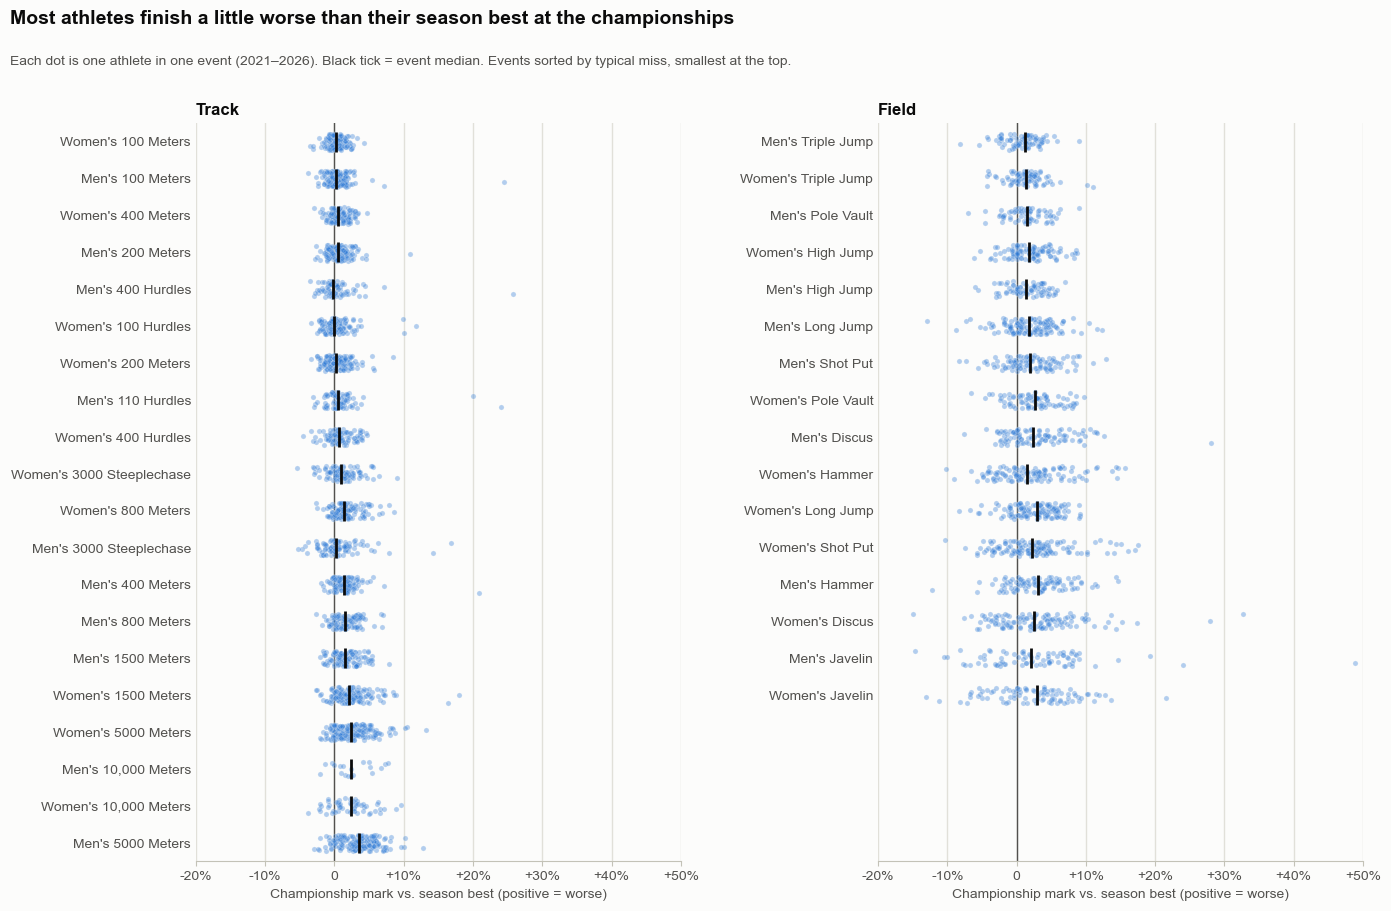

In [9]:
import matplotlib.pyplot as plt

INK, INK_2 = '#0b0b0b', '#52514e'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
DOT = '#2a78d6'

rng = np.random.default_rng(0)  # fixed jitter, so the plot is the same every run
panels = [('track', 'Track'), ('field', 'Field')]
max_rows = max(direct.loc[direct['event_type'] == t, 'event'].nunique() for t, _ in panels)
x_lo = np.floor(direct['pct_off_sb'].min() / 5) * 5
x_hi = np.ceil(direct['pct_off_sb'].max() / 5) * 5

style = {'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10,
         'axes.edgecolor': AXIS, 'xtick.color': AXIS, 'ytick.color': AXIS,
         'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2}
with plt.rc_context(style):
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.34 * max_rows + 2.4), facecolor=SURFACE)
    for ax, (event_type, title) in zip(axes, panels):
        df = direct[direct['event_type'] == event_type]
        order = per_event_direct.loc[event_type].sort_values('Typical miss (%)').index
        row = {event: i for i, event in enumerate(order)}
        y = df['event'].map(row) + rng.uniform(-0.22, 0.22, len(df))
        medians = df.groupby('event')['pct_off_sb'].median()

        ax.set_facecolor(SURFACE)
        ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
        ax.scatter(df['pct_off_sb'], y, s=14, color=DOT, alpha=0.35,
                   edgecolors=SURFACE, linewidths=0.4, zorder=2)
        ax.scatter(medians.values, medians.index.map(row), marker='|', s=220,
                   color=INK, linewidths=2, zorder=3)

        ax.set_yticks(range(len(order)), order)
        ax.set_ylim(max_rows - 0.5, -0.5)
        ax.set_xlim(x_lo, x_hi)
        ax.xaxis.set_major_formatter(lambda v, _: f'{v:+.0f}%' if v else '0')
        ax.set_xlabel('Championship mark vs. season best (positive = worse)', color=INK_2)
        ax.grid(axis='x', color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.set_title(title, loc='left', color=INK, fontsize=12, fontweight='bold')

    fig.text(0.01, 0.985, 'Most athletes finish a little worse than their season best at the championships',
             color=INK, fontsize=14, fontweight='bold', va='top')
    fig.text(0.01, 0.935, f'Each dot is one athlete in one event ({TRAIN_YEARS[0]}–{TEST_YEAR}). '
             'Black tick = event median. Events sorted by typical miss, smallest at the top.',
             color=INK_2, fontsize=10, va='top')
    fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=3)
    plt.show()

### What this shows

- **The ranking holds with five training years.** On 2026: season best 0.59 ≈ wind-legal season best 0.59 > median 0.56 > mean of last 3 meets 0.54. Most recent meet is well behind at 0.39.
- **No sign of overfitting:** the 2026 test score (0.59) is a little higher than the fit on 2021–2025 (0.55).
- **Fitting matters more than which feature.** Season best as-is scores 0.35 on 2026, vs 0.59 for the fitted season-best line. About 70% of athletes finish below their season best every year (median 1.2% worse), and the line learns that drop-off. Half of the as-is error in 2026 is that consistent per-event offset.
- **The combined model is only slightly better than the per-event season-best line** (0.60 vs 0.59; better in 18 of 35 events). It uses 8 shared coefficients instead of 70 per-event ones.
- **Some years are harder than others.** Season best as-is ranges from 0.20 (2022, the hottest meet, when 81% of athletes finished below their season best) to 0.43 (2021).
- **Weak spots:** women's 10,000m (11 athletes, negative for every predictor), men's 800m, and the 200s.
